In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
dataset= read.csv("/content/dataset2.csv")

In [2]:
head(dataset)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<chr>,<chr>,<chr>,<dbl>
1,STAT1,2.49,0.16,0.28,1.07
2,IL6,?,0.35,NA,0.99
3,TNF,missing,3.78,?,2.01
4,IRF7,?,NA,missing,0.93
5,CXCL10,missing,3.68,1.0,1.12
6,IL1B,missing,?,3.29,1.17


**Data Cleaning
**

In [3]:
mode(dataset)

[1] "list"

In [4]:
dataset1= apply(dataset,2,function(x)as.numeric(gsub('?','',x)))

Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”


In [5]:
head(dataset1)

Gene,Condition_A,Condition_B,Condition_C,Immune_Response
NA,2.49,0.16,0.28,1.07
NA,NA,0.35,NA,0.99
NA,NA,3.78,NA,2.01
NA,NA,NA,NA,0.93
NA,NA,3.68,1.00,1.12
NA,NA,NA,3.29,1.17


In [6]:
dataset1 = as.data.frame(dataset1)

dataset1$Gene = dataset$Gene

In [7]:
head(dataset1)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,STAT1,2.49,0.16,0.28,1.07
2,IL6,NA,0.35,NA,0.99
3,TNF,NA,3.78,NA,2.01
4,IRF7,NA,NA,NA,0.93
5,CXCL10,NA,3.68,1.00,1.12
6,IL1B,NA,NA,3.29,1.17


In [8]:
dim(dataset1)

[1] 37  5

In [9]:
varRow= apply(dataset1, 1, var, na.rm=T)

Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], ...):
“NAs introduced by coercion”
Warning message in FUN(newX[, i], 

In [10]:
constRow= (varRow==0 | is.na(varRow))

In [11]:
sum(constRow)

[1] 8

In [12]:
cleanData= dataset1[!constRow,]

In [13]:
head(cleanData)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,STAT1,2.49,0.16,0.28,1.07
2,IL6,NA,0.35,NA,0.99
3,TNF,NA,3.78,NA,2.01
5,CXCL10,NA,3.68,1.00,1.12
6,IL1B,NA,NA,3.29,1.17
7,IFNG,2.78,0.99,0.02,1.94


In [14]:
dim(cleanData)

[1] 29  5

In [15]:
sum(is.na(cleanData))
total_missing = sum(is.na(cleanData))
total_entries = nrow(cleanData) * ncol(cleanData)
missing_percentage = (total_missing / total_entries) * 100
missing_percentage

[1] 40

[1] 27.58621

In [16]:
head(dataset1)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,STAT1,2.49,0.16,0.28,1.07
2,IL6,NA,0.35,NA,0.99
3,TNF,NA,3.78,NA,2.01
4,IRF7,NA,NA,NA,0.93
5,CXCL10,NA,3.68,1.00,1.12
6,IL1B,NA,NA,3.29,1.17


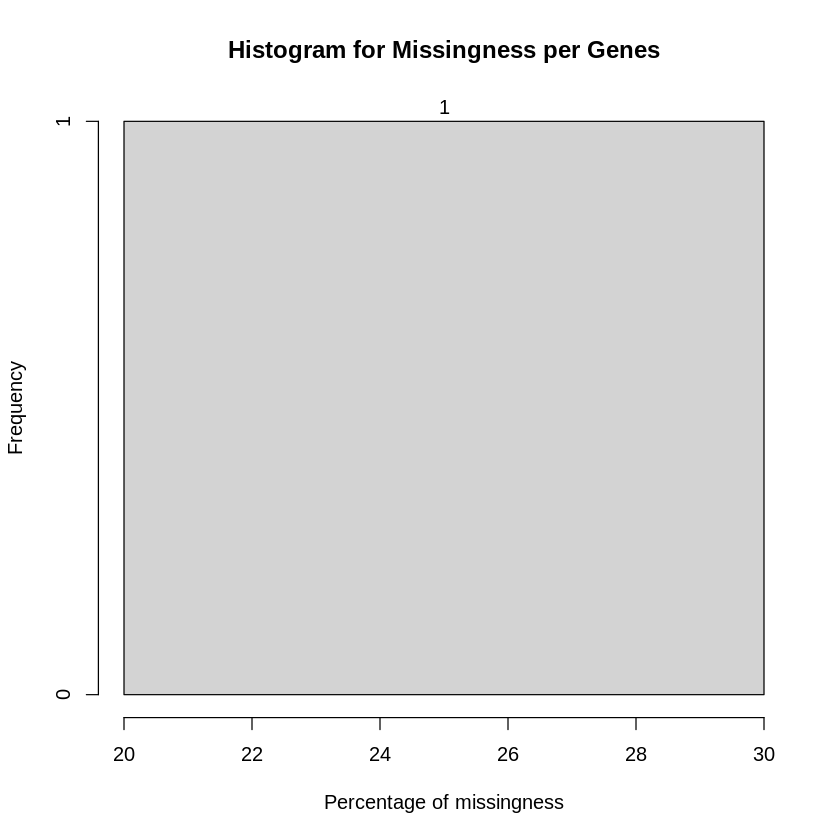

In [17]:
# Visualize the missing Values:

histogram <- hist(missing_percentage, breaks = 10,
                  main = "Histogram for Missingness per Genes",
                  xlab = "Percentage of missingness")

text(histogram$mids, histogram$counts, labels = histogram$counts, adj = c(0.5, -0.5))
abline(v = 50, col = "red", lwd = 3, lty = 2)

In [18]:
install.packages("BiocManager")

BiocManager::install("impute")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.22 (BiocManager 1.30.27), R 4.5.3 (2026-03-11)

Installing package(s) 'BiocVersion', 'impute'

Old packages: 'fs', 'nlme', 'rmarkdown', 'rpart', 'xtable'



In [19]:
library(impute)
gene_names <- cleanData$Gene
num_data <- cleanData[, -1]

num_matrix <- as.matrix(num_data)

num.mat.imputed <- impute.knn(num_matrix, k = 10)$data

imputedData <- data.frame(Gene = gene_names, num.mat.imputed)

sum(is.na(imputedData))


[1] 0

In [20]:
head(imputedData)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,STAT1,2.490000,0.160000,0.280000,1.07
2,IL6,2.583333,0.350000,1.688333,0.99
3,TNF,2.133333,3.780000,2.081250,2.01
5,CXCL10,2.225000,3.680000,1.000000,1.12
6,IL1B,2.442000,1.432857,3.290000,1.17
7,IFNG,2.780000,0.990000,0.020000,1.94


In [21]:
counts = c(0, 1, 10, 100, 1000, 200, 40, 50, 60, 100000000)
log_transformation = log2(counts + 1)
print(log_transformation)

 [1]  0.000000  1.000000  3.459432  6.658211  9.967226  7.651052  5.357552
 [8]  5.672425  5.930737 26.575425


In [22]:
install.packages("patchwork")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [23]:
library(ggplot2)
library(patchwork)

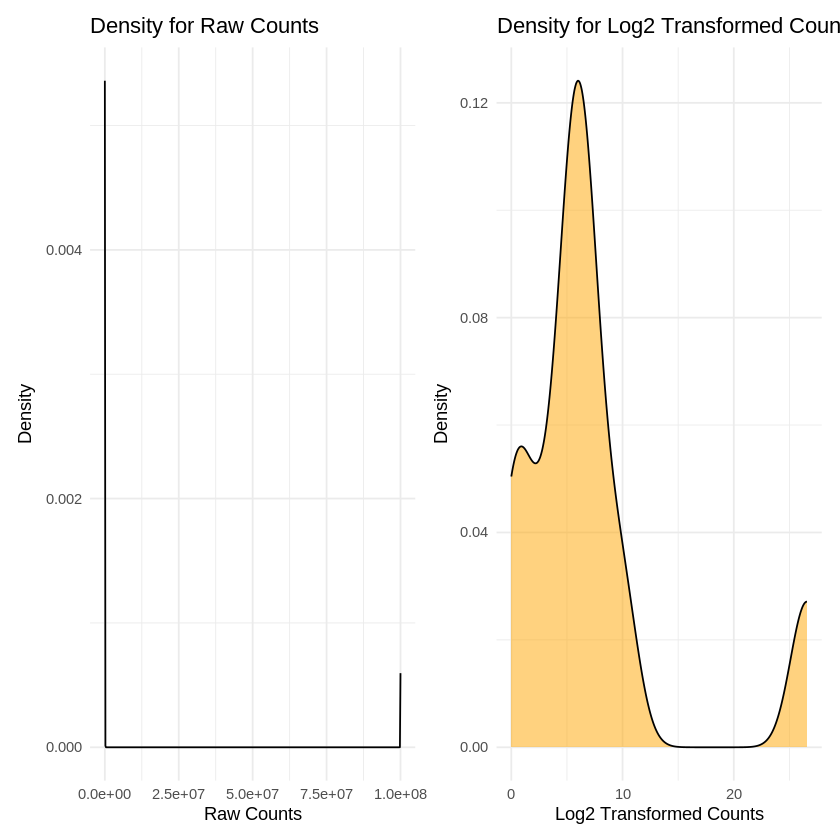

In [24]:
BeforeTransformation <- data.frame(counts = counts)
p1 <- ggplot(BeforeTransformation, aes(x = counts)) +
  geom_density(fill = "skyblue", alpha = 0.5) +
  labs(title = "Density for Raw Counts",x = "Raw Counts",y = "Density") +
  theme_minimal()

AfterTransformation <- data.frame(log_transformation = log_transformation)
p2 <- ggplot(AfterTransformation, aes(x = log_transformation)) +
  geom_density(fill = "orange", alpha = 0.5) +
  labs(title = "Density for Log2 Transformed Counts",x = "Log2 Transformed Counts",y = "Density") +
  theme_minimal()

p1 + p2

In [25]:
head(imputedData)

,Gene,Condition_A,Condition_B,Condition_C,Immune_Response
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,STAT1,2.490000,0.160000,0.280000,1.07
2,IL6,2.583333,0.350000,1.688333,0.99
3,TNF,2.133333,3.780000,2.081250,2.01
5,CXCL10,2.225000,3.680000,1.000000,1.12
6,IL1B,2.442000,1.432857,3.290000,1.17
7,IFNG,2.780000,0.990000,0.020000,1.94


In [39]:
boolean_grn_simulatorr = function(geneA_input, geneB_input, explianed = TRUE) {

  if (geneA_input == 1) {
    geneA = TRUE
  } else {
    geneA = FALSE
  }

  if (geneB_input == 1) {
    geneB = TRUE
  } else {
    geneB = FALSE
  }

  if (explianed == TRUE) {
    cat("============================================\n")
    cat("BOOLEAN GENE REGULATORY NETWORK SIMULATOR\n")
    cat("============================================\n\n")

    cat("Goal of this simulator:\n")
    cat("To explain how Gene Regulatory Networks (GRNs) work\n")
    cat("using concepts familiar to Computer Science students.\n\n")

    cat("BIOLOGICAL CONCEPT:\n")
    cat("Gene regulation occurs when genes produce proteins, such as transcription factors, that can activate or repress the expression of other genes.\n\n")

    cat("COMPUTER SCIENCE ANALOGY:\n")
    cat("Genes behave like variables in a Boolean system.\n")
    cat("Gene states are either TRUE (ON) or FALSE (OFF).\n\n")
  }

  # Activation
  if (explianed == TRUE) {
    cat("--------------------------------------------\n")
    cat("STEP 1: ACTIVATION LOGIC\n")
    cat("--------------------------------------------\n")

    cat("Biology:\n")
    cat("Gene A acts as an ACTIVATOR.\n")
    cat("If Gene A is active, it sends a signal that can turn Gene C ON.\n\n")

    cat("Computer Science Interpretation:\n")
    cat("Gene A acts like an INPUT SIGNAL in a digital circuit.\n")
    cat("If the input signal is TRUE, activation can occur.\n\n")

    cat("Current state of Gene A:", geneA, "\n\n")
  }

  activation = geneA

  if (explianed == TRUE) {
    if (activation == TRUE) {
      cat("Result: Activation signal is TRUE.\n")
      cat("Meaning Gene A is sending a signal that could activate Gene C.\n\n")
    } else {
      cat("Result: Activation signal is FALSE.\n")
      cat("Meaning Gene A is inactive, so Gene C cannot be activated by A.\n\n")
    }
  }

  # Repression
  if (explianed == TRUE) {
    cat("--------------------------------------------\n")
    cat("STEP 2: REPRESSION LOGIC\n")
    cat("--------------------------------------------\n")

    cat("Biology:\n")
    cat("Gene B acts as a REPRESSOR.\n")
    cat("A repressor can block gene expression even if an activator exists.\n\n")

    cat("Computer Science Interpretation:\n")
    cat("This is similar to an OVERRIDE rule in programming.\n")
    cat("Example: if(repressor == TRUE) then output = FALSE\n\n")

    cat("Current state of Gene B:", geneB, "\n\n")
  }

  if (geneB == TRUE) {
    geneC_state = FALSE

    if (explianed == TRUE) {
      cat("Repressor detected.\n")
      cat("Even if activation exists, the repressor overrides it.\n")
      cat("Final decision: Gene C must be OFF.\n\n")
    }

  } else {

    geneC_state = activation

    if (explianed == TRUE) {
      cat("No repressor detected.\n")
      cat("Gene C follows the activation signal from Gene A.\n\n")
    }
  }

  # Final Output
  if (explianed == TRUE) {
    cat("--------------------------------------------\n")
    cat("FINAL DECISION FOR GENE C\n")
    cat("--------------------------------------------\n")

    if (geneC_state == TRUE) {
      cat("Gene C is ON.\n\n")

      cat("Biological meaning:\n")
      cat("The gene is expressed and will produce a protein.\n\n")

    } else {
      cat("Gene C is OFF.\n\n")

      cat("Biological meaning:\n")
      cat("The gene is not expressed and no protein will be produced.\n\n")
    }

    cat("Computer Science Interpretation:\n")
    cat("Gene C behaves like the output of a Boolean circuit.\n")
    cat("Activation acts like an input signal.\n")
    cat("Repression acts like a NOT / override condition.\n\n")

    cat("In simplified logic form:\n")
    cat("GeneC = GeneA AND (NOT GeneB)\n\n")

    cat("This is equivalent to a digital logic gate system.\n")
  }

  return(list(
    GeneA = geneA,
    GeneB = geneB,
    GeneC = geneC_state
  ))
}

In [42]:
boolean_grn_simulatorr(1,1)

BOOLEAN GENE REGULATORY NETWORK SIMULATOR

Goal of this simulator:
To explain how Gene Regulatory Networks (GRNs) work
using concepts familiar to Computer Science students.

BIOLOGICAL CONCEPT:
Gene regulation occurs when genes produce proteins, such as transcription factors, that can activate or repress the expression of other genes.

COMPUTER SCIENCE ANALOGY:
Genes behave like variables in a Boolean system.
Gene states are either TRUE (ON) or FALSE (OFF).

--------------------------------------------
STEP 1: ACTIVATION LOGIC
--------------------------------------------
Biology:
Gene A acts as an ACTIVATOR.
If Gene A is active, it sends a signal that can turn Gene C ON.

Computer Science Interpretation:
Gene A acts like an INPUT SIGNAL in a digital circuit.
If the input signal is TRUE, activation can occur.

Current state of Gene A: TRUE 

Result: Activation signal is TRUE.
Meaning Gene A is sending a signal that could activate Gene C.

--------------------------------------------
STE

$GeneA
[1] TRUE

$GeneB
[1] TRUE

$GeneC
[1] FALSE

In [59]:
immune_linear_demo = function(antigen_scores, tolerance_threshold, activation_threshold, explained = TRUE){

  if(explained == TRUE){
    cat("============================================\n")
    cat("IMMUNE SYSTEM AS LINEAR REGRESSION\n")
    cat("============================================\n\n")

    cat("GOAL:\n")
    cat("Simulate immune response as a continuous output proportional to antigen strength\n")
    cat("like a linear regression model.\n\n")

    cat("BIOLOGICAL IDEA:\n")
    cat("Immune system does not act as a simple yes/no switch.\n")
    cat("It produces a graded response: low threat → weak response, high threat → strong response\n\n")

    cat("COMPUTER SCIENCE ANALOGY:\n")
    cat("Linear regression: output = slope * input + intercept\n")
    cat("Input = antigen_score, Output = response_strength\n")
    cat("Thresholds define the scaling range\n\n")
  }

  # ----------------------------
  # 1 Compute linear response
  # ----------------------------
  response_strength = (antigen_scores - tolerance_threshold) /
                       (activation_threshold - tolerance_threshold)
  response_strength = pmax(0, pmin(1, response_strength))

  if(explained == TRUE){
    cat("STEP 1: Compute linear immune response\n")
    cat("Linear scaling: response_strength = (antigen_score - tolerance) / (activation - tolerance)\n\n")
  }

  # ----------------------------
  # 2️ Determine biological state
  # ----------------------------
  bio_state = ifelse(antigen_scores <= tolerance_threshold, "SELF",
                      ifelse(antigen_scores >= activation_threshold, "NON-SELF", "UNCERTAIN"))

  if(explained == TRUE){
    cat("STEP 2: Determine biological state based on thresholds\n")
    for(i in seq_along(antigen_scores)){
      cat("Antigen Score:", antigen_scores[i], "\n")
      cat("Biological State:", bio_state[i], "\n")
      cat("Linear Response (0-1):", round(response_strength[i],3), "\n\n")
    }

    cat("CS Interpretation:\n")
    cat("- The immune response behaves like a linear regression output\n")
    cat("- Higher antigen_score → stronger response (proportional)\n")
    cat("- This models continuous graded immune activity\n")
  }

  return(list(
    antigen_scores = antigen_scores,
    biological_state = bio_state,
    response_strength = response_strength
  ))
}



In [60]:
immune_linear_demo(10,20,30)

IMMUNE SYSTEM AS LINEAR REGRESSION

GOAL:
Simulate immune response as a continuous output proportional to antigen strength
like a linear regression model.

BIOLOGICAL IDEA:
Immune system does not act as a simple yes/no switch.
It produces a graded response: low threat → weak response, high threat → strong response

COMPUTER SCIENCE ANALOGY:
Linear regression: output = slope * input + intercept
Input = antigen_score, Output = response_strength
Thresholds define the scaling range

STEP 1: Compute linear immune response
Linear scaling: response_strength = (antigen_score - tolerance) / (activation - tolerance)

STEP 2: Determine biological state based on thresholds
Antigen Score: 10 
Biological State: SELF 
Linear Response (0-1): 0 

CS Interpretation:
- The immune response behaves like a linear regression output
- Higher antigen_score → stronger response (proportional)
- This models continuous graded immune activity


$antigen_scores
[1] 10

$biological_state
[1] "SELF"

$response_strength
[1] 0

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


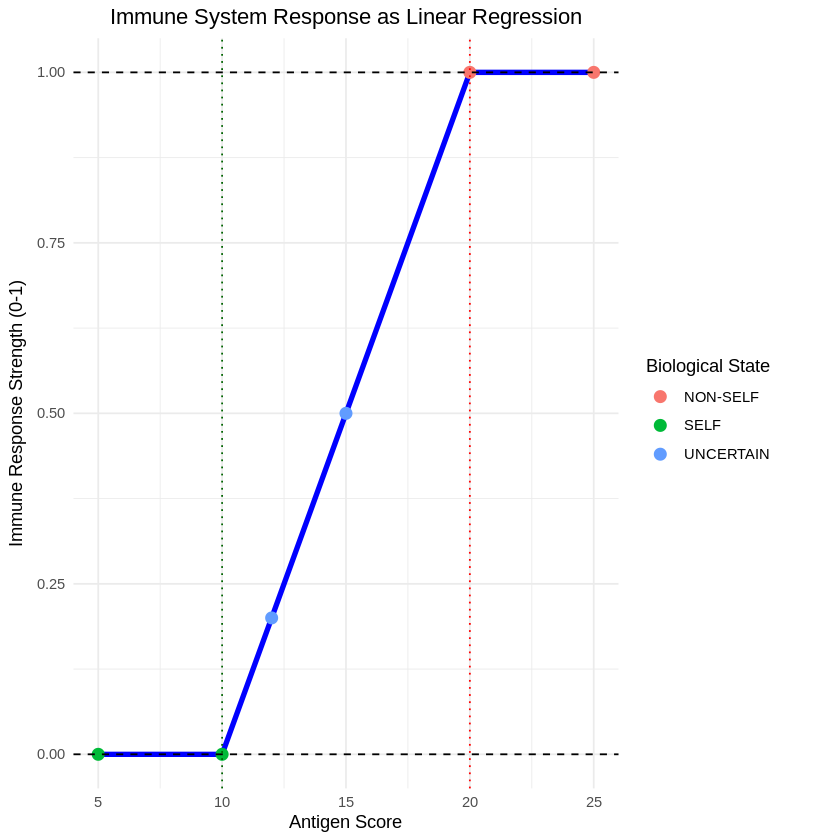

In [51]:
library(ggplot2)


df = data.frame(
  antigen_score = scores,
  response_strength = immune_demo_linear$response_strength,
  biological_state = immune_demo_linear$biological_state
)


ggplot(df, aes(x = antigen_score, y = response_strength)) +
  geom_line(color = "blue", size = 1.5) +
  geom_point(aes(color = biological_state), size = 3) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_hline(yintercept = 1, linetype = "dashed") +
  geom_vline(xintercept = 10, linetype = "dotted", color = "darkgreen") +  # tolerance
  geom_vline(xintercept = 20, linetype = "dotted", color = "red") +        # activation
  labs(
    title = "Immune System Response as Linear Regression",
    x = "Antigen Score",
    y = "Immune Response Strength (0-1)",
    color = "Biological State"
  ) +
  theme_minimal() +
  theme(plot.title = element_text(hjust = 0.5)) +
  scale_y_continuous(limits = c(0,1))